# Revision analyses v3: rhythm features in North & East Indian folk music (CICT-2026, paper 955)

Built against your notebooks 02-08 and `utils/`. Song (160 units) is the independent unit; nothing is re-extracted.

| Section | Purpose |
|---|---|
| 0 | Load `rhythm_features.parquet`; check which parameters are degenerate or redundant (derived from `feature_extraction.py`) |
| 1 | Within-song dependence (ICC, design effect) |
| 2 | Kruskal-Wallis: segment level for all 33 (reproduces Table II) and song level for the analysis set; full table to CSV |
| 3 | Post-hoc, same two-stage design as notebook 06, at song level |
| 4 | Cosine: reproduces notebook 04 (1,500-segment sample), then song-centroid and same-song split |
| 5 | K-NN: reproduces Fig. 4, then same-song neighbours removed, 10 samples, full pool |
| 6 | PCA numbers |
| 7 | The paper's held-out split (test songs per genre) and RF importance vs song-level eta-squared |
| 8 | Repeated song- and artist-grouped splits, plus an ablation without level / spectral-spread features |

In [1]:
import itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import pairwise_distances, f1_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 60)

# ---- CONFIG ----
FEATURES_PATH = "../data/extracted/rhythm_features.parquet"
META = ["genre", "state", "artist", "gender", "song", "source", "source_file"]
SEED = 42
N_PERM = 5000                 # permutation draws, cosine test
N_REPEATS = 20                # repeated song-/artist-grouped splits
TEST_FRAC = 0.20              # per-genre fraction of groups held out
TRAIN_PER_SONG = 100          # cap on training segments per song (None = all; slow for SVM)
KNN_SEEDS = 10                # random 1,500-segment samples for the K-NN sensitivity run
KNN_QUERY_PER_SONG = 100      # queries per song, full-pool K-NN run
RUN_ABLATION = True           # repeat the SVM runs without the level / spectral-spread features

# Removed from the analysis set. Reasons were derived from utils/feature_extraction.py; the table below checks them on your data.
DEGENERATE = {
    "tempogram_stability": "constant: argmax over tempogram rows includes lag 0, so std = 0 and value = 1/1e-10",
    "tempogram_mean_energy": "constant by arithmetic: each window's normalised AC sums to 0.5, so the mean is always 1/66",
    "tempogram_dominant_lag": "argmax of a decaying autocorrelation is (almost) always lag 1",
    "ac_peak_lag": "argmax of a decaying autocorrelation is (almost) always lag 1",
}
REDUNDANT = {   # feature: (partner kept, reason)
    "flux_sum": ("flux_mean", "= 129 x flux_mean"),
    "onset_density": ("onset_peak_count", "= onset_peak_count / 129"),
    "modulation_energy": ("energy_std", "~ rescaled energy_std^2 (Parseval, apart from the Nyquist bin)"),
}
ABLATE = ["energy_mean", "energy_min", "energy_max", "frame_entropy_mean"]   # overall level / per-frame spectral spread
RNG = np.random.default_rng(SEED)

## 0. Load and check the parameter set

In [2]:
rhythm_df = pd.read_parquet(FEATURES_PATH) if FEATURES_PATH.endswith(".parquet") else pd.read_csv(FEATURES_PATH)
meta = [c for c in META if c in rhythm_df.columns]
ALL34 = [c for c in rhythm_df.columns if c not in meta and pd.api.types.is_numeric_dtype(rhythm_df[c])]   # same rule as utils.get_feature_columns
assert len(ALL34) == 34, f"expected 34 feature columns, found {len(ALL34)}"
SID = "song_id"
rhythm_df[SID] = rhythm_df["genre"].astype(str) + "::" + rhythm_df["song"].astype(str)
assert rhythm_df[SID].nunique() == 160, rhythm_df[SID].nunique()
has_artist = "artist" in rhythm_df.columns
if has_artist:
    rhythm_df["artist_key"] = rhythm_df["genre"].astype(str) + "::" + rhythm_df["artist"].astype(str)
print(f"{len(rhythm_df):,} segments, {rhythm_df[SID].nunique()} songs, {len(ALL34)} feature columns")
if has_artist:
    print("Unique artists overall:", rhythm_df["artist"].nunique(), "| sum of per-genre unique artists:", rhythm_df.groupby("genre").artist.nunique().sum())

# ---- evidence for the removals ----
rows = []
for c in DEGENERATE:
    v = rhythm_df[c].round(9)
    rows.append(dict(feature=c, share_of_most_common_value=round(v.value_counts(normalize=True).iloc[0], 4),
                     distinct_values_9dp=v.nunique(), min=rhythm_df[c].min(), max=rhythm_df[c].max(), reason=DEGENERATE[c]))
print("\nDegenerate parameters:"); display(pd.DataFrame(rows))
rows = [dict(feature=c, kept_partner=p, spearman=round(stats.spearmanr(rhythm_df[c], rhythm_df[p]).correlation, 6), reason=r)
        for c, (p, r) in REDUNDANT.items()]
print("Redundant parameters:"); display(pd.DataFrame(rows))

FEATS = [c for c in ALL34 if c not in DEGENERATE and c not in REDUNDANT]          # analysis set
FEATS33 = [c for c in ALL34 if rhythm_df[c].var() > 0]                             # the paper's 33 non-constant parameters
print(f"\nAnalysis set: {len(FEATS)} parameters (paper: {len(FEATS33)})")

genres = sorted(rhythm_df.genre.unique())
song_c = pd.factorize(rhythm_df[SID])[0]
gen_c = pd.factorize(rhythm_df.genre, sort=True)[0]
cnt = np.bincount(song_c)
song_gen = pd.Series(gen_c).groupby(song_c).first().values
Z = StandardScaler().fit_transform(rhythm_df[FEATS])
Z33 = StandardScaler().fit_transform(rhythm_df[FEATS33])
summary = rhythm_df.groupby("genre").agg(songs=(SID, "nunique"), segments=("genre", "size"))
summary["segment_share_%"] = (100 * summary.segments / len(rhythm_df)).round(1)
display(summary)

109,089 segments, 160 songs, 34 feature columns
Unique artists overall: 59 | sum of per-genre unique artists: 59

Degenerate parameters:


,feature,share_of_most_common_value,distinct_values_9dp,min,max,reason
0,tempogram_stability,1.0000,1,1.000000e+10,1.000000e+10,constant: argmax over tempogram rows includes ...
1,tempogram_mean_energy,0.2800,101,0.000000e+00,1.515205e-02,constant by arithmetic: each window's normalis...
2,tempogram_dominant_lag,0.9994,8,1.000000e+00,1.100000e+01,argmax of a decaying autocorrelation is (almos...
3,ac_peak_lag,0.9805,40,1.000000e+00,4.500000e+01,argmax of a decaying autocorrelation is (almos...


Redundant parameters:


,feature,kept_partner,spearman,reason
0,flux_sum,flux_mean,1.0,= 129 x flux_mean
1,onset_density,onset_peak_count,1.0,= onset_peak_count / 129
2,modulation_energy,energy_std,1.0,"~ rescaled energy_std^2 (Parseval, apart from ..."



Analysis set: 27 parameters (paper: 33)


,songs,segments,segment_share_%
genre,,,
Bauls,20,8450,7.7
Bhatiali,20,8808,8.1
Gidha,20,8228,7.5
Kajri,20,20580,18.9
Maand,20,17796,16.3
Sohar,20,12994,11.9
Sufi,20,19213,17.6
Uttarakhandi,20,13020,11.9


In [13]:
rng = np.random.default_rng(42)
sw = []
for g, d in rhythm_df.groupby("genre"):
    idx = rng.choice(len(d), size=500, replace=False)
    for f in FEATS:
        x = d[f].to_numpy()[idx]
        sw.append((f, g, stats.shapiro(x).pvalue if np.ptp(x) > 0 else np.nan))
sw = pd.DataFrame(sw, columns=["feature", "genre", "p"])
lev = pd.DataFrame([(f, stats.levene(*[d[f].values for _, d in rhythm_df.groupby("genre")]).pvalue)
                    for f in FEATS], columns=["feature", "p"])
n_sw, n_lev = sw.p.notna().sum(), lev.p.notna().sum()
print(f"Shapiro-Wilk: {(sw.p < .05).sum()} of {n_sw} parameter-genre tests significant ({(sw.p < .05).sum() / n_sw:.1%})")
print(f"Levene: {(lev.p < .05).sum()} of {n_lev} parameters significant ({(lev.p < .05).sum() / n_lev:.1%})")

Shapiro-Wilk: 209 of 216 parameter-genre tests significant (96.8%)
Levene: 27 of 27 parameters significant (100.0%)


## 1. Within-song dependence

In [3]:
def icc1(x, g):
    x = pd.Series(np.asarray(x)); g = pd.Series(np.asarray(g))
    grp = x.groupby(g); n_i = grp.size().values; k = len(n_i); N = n_i.sum()
    ssb = (n_i * (grp.mean().values - x.mean()) ** 2).sum()
    ssw = ((x - grp.transform("mean")) ** 2).sum()
    msb, msw = ssb / (k - 1), ssw / (N - k)
    n0 = (N - (n_i ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)

icc = pd.Series({f: icc1(rhythm_df[f], song_c) for f in FEATS})
nbar = len(rhythm_df) / rhythm_df[SID].nunique()
deff = 1 + (nbar - 1) * icc.clip(lower=0)
print(f"ICC(song): median {icc.median():.2f}, range {icc.min():.2f} to {icc.max():.2f}")
print(f"Design effect (median) {deff.median():.0f} -> effective n ~ {len(rhythm_df) / deff.median():,.0f} of {len(rhythm_df):,} segments")

ICC(song): median 0.31, range 0.08 to 0.75
Design effect (median) 212 -> effective n ~ 515 of 109,089 segments


## 2. Kruskal-Wallis: segment level (all 33) and song level (analysis set)

In [4]:
def bh(p):
    p = np.asarray(p, float); o = np.argsort(p); r = np.empty_like(o); r[o] = np.arange(len(p))
    q = p[o] * len(p) / (np.arange(len(p)) + 1)
    return np.minimum(np.minimum.accumulate(q[::-1])[::-1], 1)[r]

def kw(groups):
    H, p = stats.kruskal(*groups); return H, p

k = len(genres)
# (a) segment level, all 33 non-constant parameters (reproduces Table II; pseudoreplicated, descriptive only)
seg = []
for f in FEATS33:
    H, p = kw([g[f].values for _, g in rhythm_df.groupby("genre")])
    seg.append(dict(feature=f, H_segment=H, p_segment=p, eta2_segment=max(0.0, (H - k + 1) / (len(rhythm_df) - k))))
seg = pd.DataFrame(seg); seg["p_fdr_segment"] = bh(seg.p_segment)
print(f"Segment level: {(seg.p_fdr_segment < .05).sum()} of {len(seg)} parameters significant after BH-FDR (paper: 32 of 33)")

# (b) song level (n = 160), analysis set only. One row per song = median of its segments.
S = rhythm_df.groupby(["genre", SID])[FEATS].median().reset_index()
assert (S[FEATS].nunique() > 1).all(), S[FEATS].nunique()[S[FEATS].nunique() <= 1]
n = len(S); song = []
for f in FEATS:
    H, p = kw([g[f].values for _, g in S.groupby("genre")])
    song.append(dict(feature=f, H_song=H, p_song=p, eta2_song=(H - k + 1) / (n - k), ICC=icc[f]))
song = pd.DataFrame(song); song["p_fdr_song"] = bh(song.p_song)

flag = {**{c: "degenerate: " + r for c, r in DEGENERATE.items()}, **{c: f"redundant with {p}" for c, (p, r) in REDUNDANT.items()}}
T = seg.merge(song, on="feature", how="left")
T["note"] = T.feature.map(flag).fillna("")
T = T.sort_values("eta2_song", ascending=False, na_position="last").reset_index(drop=True)
T.round(4).to_csv("table_all_parameters.csv", index=False)       # full table for the appendix / repo
print(f"Song level (n={n}): {(song.p_fdr_song < .05).sum()} of {len(song)} parameters significant after BH-FDR")
print(f"Song-level eta2 >= 0.06: {(song.eta2_song >= .06).sum()} | >= 0.14: {(song.eta2_song >= .14).sum()} | max {song.eta2_song.max():.3f} (segment-level max {seg.eta2_segment.max():.3f})")
display(T.round(4))

Segment level: 32 of 33 parameters significant after BH-FDR (paper: 32 of 33)
Song level (n=160): 21 of 27 parameters significant after BH-FDR
Song-level eta2 >= 0.06: 20 | >= 0.14: 5 | max 0.236 (segment-level max 0.155)


,feature,H_segment,p_segment,eta2_segment,p_fdr_segment,H_song,p_song,eta2_song,ICC,p_fdr_song,note
0,energy_min,16946.3684,0.0000,0.1553,0.0000,42.8562,0.0000,0.2359,0.4527,0.0000,
1,tempogram_var,9412.2853,0.0000,0.0862,0.0000,34.3434,0.0000,0.1799,0.2513,0.0002,
2,energy_mean,15721.3503,0.0000,0.1441,0.0000,32.9439,0.0000,0.1707,0.6338,0.0002,
3,frame_entropy_mean,16316.4317,0.0000,0.1495,0.0000,30.2476,0.0001,0.1529,0.7529,0.0006,
4,energy_max,15038.4151,0.0000,0.1378,0.0000,29.4402,0.0001,0.1476,0.6874,0.0006,
5,rhythm_hist_dominant_value,7670.5301,0.0000,0.0703,0.0000,27.5987,0.0003,0.1355,0.3095,0.0012,
6,modulation_centroid,7211.4717,0.0000,0.0660,0.0000,26.8987,0.0003,0.1309,0.2384,0.0013,
7,energy_range,6379.9081,0.0000,0.0584,0.0000,22.9579,0.0017,0.1050,0.2796,0.0055,
8,onset_peak_count,7310.9335,0.0000,0.0670,0.0000,22.8037,0.0018,0.1040,0.3230,0.0055,
9,rhythm_hist_std,6406.1612,0.0000,0.0587,0.0000,22.4615,0.0021,0.1017,0.3039,0.0057,


## 3. Post-hoc pairwise tests at song level

In [5]:
# Two-stage design used in notebook 06: omnibus BH across parameters, then post-hoc Mann-Whitney U with BH
# across the 28 genre pairs *within each* omnibus-significant parameter. Run at song level.
sig = song.loc[song.p_fdr_song < .05, "feature"].tolist()
pairs = list(itertools.combinations(genres, 2)); rows = []
for f in sig:
    recs = []
    for a, b in pairs:
        x = S.loc[S.genre == a, f].values; y = S.loc[S.genre == b, f].values
        U, p = stats.mannwhitneyu(x, y, alternative="two-sided")
        recs.append((f, a, b, p, 2 * U / (len(x) * len(y)) - 1))      # + means genre_a higher (notebook 06 used the opposite sign)
    d = pd.DataFrame(recs, columns=["feature", "genre_a", "genre_b", "p", "rank_biserial_a_higher"])
    d["p_fdr"] = bh(d.p); rows.append(d)
P = pd.concat(rows, ignore_index=True); P["significant"] = P.p_fdr < .05
P.round(5).to_csv("table_posthoc_song_level.csv", index=False)
M = P.groupby(["genre_a", "genre_b"]).significant.sum().unstack()
print(f"Parameters (of {len(sig)} omnibus-significant) that differ for each genre pair (song-level MWU, BH within parameter):")
display(M.fillna(""))
print("Pairs significant per parameter:"); display(P.groupby("feature").significant.sum().sort_values(ascending=False))
print("Median |rank-biserial| over significant tests:", P.loc[P.significant, "rank_biserial_a_higher"].abs().median().round(2))

Parameters (of 21 omnibus-significant) that differ for each genre pair (song-level MWU, BH within parameter):


genre_b,Bhatiali,Gidha,Kajri,Maand,Sohar,Sufi,Uttarakhandi
genre_a,,,,,,,
Bauls,2.0,2.0,1.0,3.0,1.0,5.0,7.0
Bhatiali,,7.0,2.0,2.0,4.0,6.0,5.0
Gidha,,,1.0,3.0,1.0,5.0,6.0
Kajri,,,,0.0,4.0,0.0,2.0
Maand,,,,,5.0,1.0,0.0
Sohar,,,,,,9.0,10.0
Sufi,,,,,,,2.0


Pairs significant per parameter:


feature
energy_min                    13
tempogram_var                  9
energy_mean                    9
rhythm_hist_dominant_value     8
energy_max                     6
modulation_centroid            6
frame_entropy_mean             6
ac_mean                        4
ac_std                         4
ac_peak_value                  4
rhythm_hist_entropy            4
onset_peak_count               4
energy_range                   4
rhythm_hist_std                4
temporal_entropy               4
energy_skew                    3
frame_entropy_std              2
onset_mean                     1
flux_mean                      1
energy_std                     0
rhythm_hist_dominant_bin       0
Name: significant, dtype: int64

Median |rank-biserial| over significant tests: 0.56


## 4. Cosine similarity

[reproduction] 1,500-segment sample: within 0.0737 | across 0.0032   (paper: 0.0737 | 0.0031)
[reproduction] K-NN agreement (paper: Sufi .4317, Maand .3483, Uttarakhandi .3416, Sohar .3376, Kajri .3269, Gidha .2860, Bhatiali .2775, Bauls .1741)


,agreement
Sufi,0.4317
Maand,0.3483
Uttarakhandi,0.3416
Sohar,0.3376
Kajri,0.3269
Gidha,0.2860
Bhatiali,0.2775
Bauls,0.1741



SONG-CENTROID cosine: within 0.111 | across -0.007 | diff 0.117 | P(within > across) = 0.57 | permutation p = 0.0002
SEGMENT PAIRS: same song 0.375 | same genre, different song 0.047 | different genre 0.003 | P(same-genre > different-genre, same-song pairs excluded) = 0.53


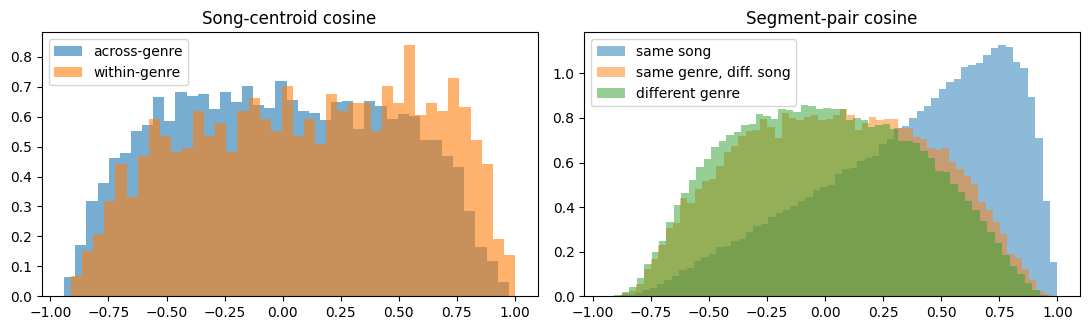

In [6]:
def z_utils(M):                                   # identical to utils.similarity.z_score_normalize
    m, s = M.mean(axis=0), M.std(axis=0); s[s == 0] = 1e-10
    return (M - m) / s

def cos_within_across(Xs, labels):
    Xn = Xs / np.where(np.linalg.norm(Xs, axis=1, keepdims=True) == 0, 1e-10, np.linalg.norm(Xs, axis=1, keepdims=True))
    C = Xn @ Xn.T; same = labels[:, None] == labels[None, :]; np.fill_diagonal(same, False)
    iu = np.triu_indices(len(Xs), 1)
    return C[iu][same[iu]], C[iu][~same[iu]]

# (a) reproduce notebook 04: 1,500 random segments (seed 42), all 34 z-scored columns
X34 = z_utils(rhythm_df[ALL34].to_numpy(float))
sample_idx = np.sort(np.random.default_rng(42).choice(len(X34), size=1500, replace=False))
meta_s = rhythm_df.iloc[sample_idx].reset_index(drop=True); lab_s = np.asarray(meta_s.genre, dtype=object)
w, a = cos_within_across(X34[sample_idx], lab_s)
print(f"[reproduction] 1,500-segment sample: within {w.mean():.4f} | across {a.mean():.4f}   (paper: 0.0737 | 0.0031)")
ind = NearestNeighbors(n_neighbors=6).fit(X34[sample_idx]).kneighbors(X34[sample_idx], return_distance=False)[:, 1:]
agree = pd.Series((lab_s[ind] == lab_s[:, None]).mean(1)).groupby(lab_s).mean().sort_values(ascending=False)
print("[reproduction] K-NN agreement (paper: Sufi .4317, Maand .3483, Uttarakhandi .3416, Sohar .3376, Kajri .3269, Gidha .2860, Bhatiali .2775, Bauls .1741)")
display(agree.round(4).to_frame("agreement"))

# (b) song-level: song centroid of z-scored segments (analysis set), permutation test on genre labels
C = pd.DataFrame(Z).groupby(song_c).mean().values
Cn = C / np.linalg.norm(C, axis=1, keepdims=True); CS = Cn @ Cn.T
iu = np.triu_indices(len(Cn), 1); vals = CS[iu]; same = (song_gen[:, None] == song_gen[None, :])[iu]
wi, ac = vals[same], vals[~same]
auc = stats.mannwhitneyu(wi, ac).statistic / (len(wi) * len(ac)); obs = wi.mean() - ac.mean(); perm = np.empty(N_PERM)
for i in range(N_PERM):
    lab = RNG.permutation(song_gen); s = (lab[:, None] == lab[None, :])[iu]; perm[i] = vals[s].mean() - vals[~s].mean()
p_perm = (1 + (perm >= obs).sum()) / (N_PERM + 1)
print(f"\nSONG-CENTROID cosine: within {wi.mean():.3f} | across {ac.mean():.3f} | diff {obs:.3f} | P(within > across) = {auc:.2f} | permutation p = {p_perm:.4f}")

# (c) segment pairs, same-song pairs separated (analysis set)
M_ = 200_000
order = np.argsort(song_c, kind="stable"); starts = np.r_[0, np.cumsum(cnt)[:-1]]
Zn = Z / np.linalg.norm(Z, axis=1, keepdims=True)
i = RNG.integers(0, len(Z), M_); j = RNG.integers(0, len(Z), M_)
cs = (Zn[i] * Zn[j]).sum(1); ss = song_c[i] == song_c[j]; sg = gen_c[i] == gen_c[j]
js = order[starts[song_c[i]] + (RNG.random(M_) * cnt[song_c[i]]).astype(int)]
cs_same = (Zn[i] * Zn[js]).sum(1); wg, ag = cs[sg & ~ss], cs[~sg]
auc_seg = stats.mannwhitneyu(wg, ag).statistic / (len(wg) * len(ag))
print(f"SEGMENT PAIRS: same song {cs_same.mean():.3f} | same genre, different song {wg.mean():.3f} | different genre {ag.mean():.3f} | P(same-genre > different-genre, same-song pairs excluded) = {auc_seg:.2f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(ac, 40, alpha=.6, density=True, label="across-genre"); ax[0].hist(wi, 40, alpha=.6, density=True, label="within-genre")
ax[0].set_title("Song-centroid cosine"); ax[0].legend()
for v, l in [(cs_same, "same song"), (wg, "same genre, diff. song"), (ag, "different genre")]:
    ax[1].hist(v, 60, alpha=.5, density=True, label=l)
ax[1].set_title("Segment-pair cosine"); ax[1].legend(); plt.tight_layout(); plt.show()

## 5. K-NN genre cohesion

In [8]:
K = 5
def knn_sample(Zs, labels, songs):
    """K-NN genre agreement inside a sample: own-song neighbours allowed vs removed, with prior-aware chance."""
    order = np.argsort(pairwise_distances(Zs), axis=1)
    out = np.zeros((len(Zs), 4))
    for i in range(len(Zs)):
        cand = order[i][order[i] != i]
        out[i, 0] = np.mean(labels[cand[:K]] == labels[i])                      # own-song neighbours allowed
        out[i, 3] = np.mean(songs[cand[:K]] == songs[i])                        # share of neighbours from own song
        cand = cand[songs[cand] != songs[i]][:K]
        out[i, 1] = np.mean(labels[cand] == labels[i])                          # own-song neighbours removed
        out[i, 2] = np.mean(labels[songs != songs[i]] == labels[i])             # chance = genre share among other songs
    return pd.DataFrame(out, columns=["allowed", "excluded", "chance", "own_song_share"]).groupby(labels).mean()

songs_all = np.asarray(rhythm_df[SID], dtype=object); labels_all = np.asarray(rhythm_df.genre, dtype=object)
runs = []
for sd in range(KNN_SEEDS):
    idx = sample_idx if sd == 0 else np.sort(np.random.default_rng(1000 + sd).choice(len(Z), size=1500, replace=False))
    runs.append(knn_sample(Z[idx], labels_all[idx], songs_all[idx]))
mean = sum(runs) / len(runs); sd_ = pd.concat(runs).groupby(level=0).std()
tab = pd.concat({"mean": mean, "sd": sd_}, axis=1)
print(f"1,500-segment samples ({KNN_SEEDS} seeds; seed 0 = the paper's sample), analysis set, k=5. Agreement in %:")
display((mean * 100).round(1).sort_values("excluded", ascending=False))
print("SD over samples, %:"); display((sd_ * 100).round(1))
print(f"Overall: own-song neighbours allowed {mean.allowed.mean():.1%} -> removed {mean.excluded.mean():.1%} (prior-aware chance {mean.chance.mean():.1%}; naive 12.5%)")

# full pool: all 109k segments as candidate neighbours, own song removed (the strictest, least noisy estimate)
def knn_full(Zf):
    q = np.concatenate([RNG.choice(np.where(song_c == s)[0], min(KNN_QUERY_PER_SONG, cnt[s]), replace=False) for s in range(len(cnt))])
    ex, ch = np.empty(len(q)), np.empty(len(q)); qs = song_c[q]
    for s in range(len(cnt)):
        pos = np.where(qs == s)[0]; pool = np.where(song_c != s)[0]
        nb = NearestNeighbors(n_neighbors=K, algorithm="brute").fit(Zf[pool]).kneighbors(Zf[q[pos]], return_distance=False)
        ex[pos] = (gen_c[pool][nb] == song_gen[s]).mean(1); ch[pos] = (gen_c[pool] == song_gen[s]).mean()
    return pd.DataFrame({"genre": np.array(genres)[gen_c[q]], "excluded": ex, "chance": ch}).groupby("genre").mean()
R_full = knn_full(Z); R_full["excess"] = R_full.excluded - R_full.chance
print("\nFull pool, own song removed, %:"); display((R_full * 100).round(1).sort_values("excluded", ascending=False))

1,500-segment samples (10 seeds; seed 0 = the paper's sample), analysis set, k=5. Agreement in %:


,allowed,excluded,chance,own_song_share
Sohar,34.6,27.3,11.0,10.9
Sufi,40.1,25.3,16.5,21.4
Uttarakhandi,33.5,22.5,11.3,14.7
Gidha,35.3,21.5,6.9,18.7
Maand,32.7,21.2,15.1,15.0
Kajri,34.8,19.2,18.4,19.2
Bhatiali,24.5,13.3,7.8,12.8
Bauls,18.5,10.8,7.1,8.9


SD over samples, %:


,allowed,excluded,chance,own_song_share
Bauls,3.4,1.9,0.6,2.7
Bhatiali,5.9,4.1,0.9,3.4
Gidha,4.4,3.5,0.8,2.7
Kajri,1.6,1.8,1.3,1.6
Maand,3.2,2.0,1.1,2.7
Sohar,2.7,2.2,1.0,1.6
Sufi,3.8,3.6,0.9,2.6
Uttarakhandi,2.8,1.8,0.7,1.9


Overall: own-song neighbours allowed 31.8% -> removed 20.1% (prior-aware chance 11.8%; naive 12.5%)

Full pool, own song removed, %:


,excluded,chance,excess
genre,,,
Sohar,40.4,11.4,29.0
Gidha,33.2,7.2,26.0
Uttarakhandi,28.9,11.4,17.5
Sufi,27.0,16.9,10.1
Maand,24.7,15.6,9.1
Kajri,24.4,18.1,6.4
Bhatiali,21.9,7.7,14.2
Bauls,14.0,7.4,6.6


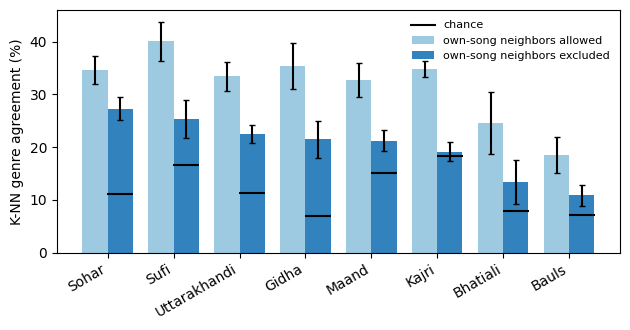

In [9]:
import os
os.makedirs("figures", exist_ok=True)
order = mean.sort_values("excluded", ascending=False).index
x, w = np.arange(len(order)), 0.38
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(x - w/2, mean.loc[order, "allowed"] * 100, w, yerr=sd_.loc[order, "allowed"] * 100, capsize=2,
       color="#9ecae1", label="own-song neighbors allowed")
ax.bar(x + w/2, mean.loc[order, "excluded"] * 100, w, yerr=sd_.loc[order, "excluded"] * 100, capsize=2,
       color="#3182bd", label="own-song neighbors excluded")
ax.scatter(x + w/2, mean.loc[order, "chance"] * 100, marker="_", s=350, color="k", zorder=3, label="chance")
ax.set_xticks(x, order, rotation=30, ha="right")
ax.set_ylabel("K-NN genre agreement (%)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("figures/fig_knn.png", dpi=300, bbox_inches="tight")

## 6. PCA numbers

In [10]:
def pca_report(Zm, name):
    ev = PCA().fit(Zm).explained_variance_ratio_; cum = np.cumsum(ev)
    print(f"{name}: PC1 {ev[0]:.1%} | PC2 {ev[1]:.1%} | PC1+PC2 {cum[1]:.1%} | 10 PCs {cum[9]:.1%} | PCs for 80/90/95%: "
          f"{np.searchsorted(cum, .8) + 1}/{np.searchsorted(cum, .9) + 1}/{np.searchsorted(cum, .95) + 1}")
pca_report(Z33, f"paper set ({Z33.shape[1]} parameters)")
pca_report(Z, f"analysis set ({Z.shape[1]} parameters)")

paper set (33 parameters): PC1 27.9% | PC2 21.7% | PC1+PC2 49.6% | 10 PCs 87.1% | PCs for 80/90/95%: 8/12/15
analysis set (27 parameters): PC1 30.3% | PC2 23.4% | PC1+PC2 53.7% | 10 PCs 91.5% | PCs for 80/90/95%: 6/10/13


## 7. The paper's held-out split and importance ranking

In [11]:
# (a) the paper's held-out split (notebook 08: GroupShuffleSplit, 20% of songs, seed 42, no genre stratification)
groups = np.asarray(rhythm_df[SID], dtype=object)
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(np.zeros(len(gen_c)), gen_c, groups))
ts = pd.DataFrame({"genre": np.asarray(rhythm_df.genre, dtype=object)[te], "song": groups[te]})
print("Paper's held-out split:", ts.song.nunique(), "songs,", len(te), "segments")
display(pd.DataFrame({"test_songs": ts.groupby("genre").song.nunique(), "test_segments": ts.groupby("genre").size()}).reindex(genres))

# (b) Random-Forest importance vs the song-level eta-squared ranking (pure eta-squared, not the combined rank used in notebook 08)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
rf.fit(StandardScaler().fit_transform(rhythm_df[FEATS].values[tr]), gen_c[tr])
imp = pd.DataFrame({"feature": FEATS, "rf_importance": rf.feature_importances_}).sort_values("rf_importance", ascending=False).reset_index(drop=True)
imp["rf_rank"] = imp.index + 1
cmp_ = imp.merge(song[["feature", "eta2_song"]], on="feature"); cmp_["eta2_rank"] = cmp_.eta2_song.rank(ascending=False).astype(int)
ov = set(cmp_.nsmallest(10, "rf_rank").feature) & set(cmp_.nsmallest(10, "eta2_rank").feature)
print(f"Top-10 overlap, RF importance vs song-level eta2: {len(ov)}/10 -> {sorted(ov)}")
display(cmp_.sort_values("rf_rank").head(12).round(4))

Paper's held-out split: 32 songs, 18256 segments


,test_songs,test_segments
genre,,
Bauls,6,2324
Bhatiali,4,1300
Gidha,3,755
Kajri,3,3063
Maand,4,1972
Sohar,5,3609
Sufi,3,3165
Uttarakhandi,4,2068


Top-10 overlap, RF importance vs song-level eta2: 5/10 -> ['energy_max', 'energy_mean', 'energy_min', 'frame_entropy_mean', 'tempogram_var']


,feature,rf_importance,rf_rank,eta2_song,eta2_rank
0,frame_entropy_mean,0.0996,1,0.1529,4
1,flux_mean,0.0658,2,0.0721,20
2,modulation_dominant_freq_bin,0.0651,3,0.0088,26
3,frame_entropy_std,0.0595,4,0.0845,16
4,energy_mean,0.0537,5,0.1707,3
5,energy_skew,0.0470,6,0.0958,14
6,energy_max,0.0453,7,0.1476,5
7,energy_min,0.0421,8,0.2359,1
8,tempogram_var,0.0403,9,0.1799,2
9,onset_mean,0.0399,10,0.0591,21


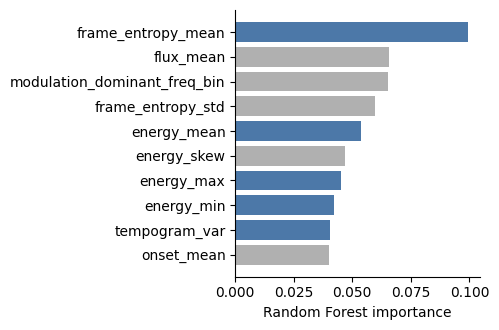

In [15]:
import matplotlib.pyplot as plt, seaborn as sns
top = cmp_.sort_values("rf_importance", ascending=False).head(10)
in_both = top["eta2_rank"] <= 10          # also top-10 by song-level eta^2
cols = ["#4C78A8" if b else "#B0B0B0" for b in in_both]
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.barh(top["feature"][::-1], top["rf_importance"][::-1], color=cols[::-1])
ax.set_xlabel("Random Forest importance")
ax.set_ylabel("")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("image9.png", dpi=300)

## 8. Repeated grouped splits

In [12]:
# ===== Section 8 (fast version): repeated song-/artist-grouped splits =====
# Paste into the v3 notebook in place of the two cells of section 8.
# Needs these already defined by earlier cells: rhythm_df, FEATS, SID, song_c, gen_c, genres, has_artist, ABLATE, SEED
import time, itertools
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, confusion_matrix

# ---- speed settings ----
N_REPEATS      = 50
TRAIN_PER_SONG = 100     # matches the original notebook
TEST_PER_SONG  = 200
TEST_FRAC      = 0.20
RUN_ARTIST     = True    # runs second, after the song-grouped run
RUN_ABLATION   = False   # skip it, it's the optional extra

y = gen_c
rng_global = np.random.default_rng(SEED)

def make_split(group_col, rng):
    g = rhythm_df[["genre", group_col]].drop_duplicates(); test = []
    for _, sub in g.groupby("genre"):
        ids = sub[group_col].values
        test += list(rng.choice(ids, max(1, int(round(TEST_FRAC * len(ids)))), replace=False))
    return rhythm_df[group_col].isin(test).values

def cap_per_song(idx, rng, cap):
    """keep at most `cap` randomly chosen segments of each song among row indices idx"""
    perm = rng.permutation(idx)
    rank = pd.Series(perm).groupby(song_c[perm]).cumcount().values
    return perm[rank < cap]

def make_models(names):
    all_ = {
        "SVM (RBF)": lambda: SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced"),
        "Random Forest": lambda: RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        "Dummy (stratified)": lambda: DummyClassifier(strategy="stratified", random_state=SEED),
        "Dummy (most frequent)": lambda: DummyClassifier(strategy="most_frequent"),
    }
    return {n: all_[n] for n in names}

def run(group_col, feats, names, label):
    X = rhythm_df[feats].values; mods = make_models(names)
    rng = np.random.default_rng(SEED); recs, f1g = [], []
    cms = {m: np.zeros((len(genres), len(genres))) for m in mods}
    t0 = time.time()
    for r in range(N_REPEATS):
        te = make_split(group_col, rng); tr_idx, te_idx = np.where(~te)[0], np.where(te)[0]
        tr_idx = cap_per_song(tr_idx, rng, TRAIN_PER_SONG)
        te_idx = cap_per_song(te_idx, rng, TEST_PER_SONG)
        sc = StandardScaler().fit(X[tr_idx]); Xtr, Xte = sc.transform(X[tr_idx]), sc.transform(X[te_idx])
        for name, mk in mods.items():
            pred = mk().fit(Xtr, y[tr_idx]).predict(Xte)
            t = pd.DataFrame({"s": song_c[te_idx], "y": y[te_idx], "p": pred})
            vote = t.groupby("s").p.agg(lambda v: v.value_counts().idxmax()); truth = t.groupby("s").y.first()
            recs.append(dict(model=name, rep=r, acc=(pred == y[te_idx]).mean(),
                             macro_f1=f1_score(y[te_idx], pred, average="macro", labels=range(len(genres)), zero_division=0),
                             song_vote_acc=(vote == truth).mean()))
            cms[name] += confusion_matrix(y[te_idx], pred, labels=range(len(genres)))
            f1g.append(dict(model=name, **dict(zip(genres, f1_score(y[te_idx], pred, average=None, labels=range(len(genres)), zero_division=0)))))
        print(f"  [{label}] repeat {r+1}/{N_REPEATS} done, {time.time()-t0:.0f}s elapsed", flush=True)
    res, f1g = pd.DataFrame(recs), pd.DataFrame(f1g)
    tag = label.replace(" ", "_").replace(",", "").replace("/", "")
    res.to_csv(f"repeated_{tag}.csv", index=False); f1g.to_csv(f"perGenreF1_{tag}.csv", index=False)   # checkpoint
    return res, cms, f1g

def report(res, label):
    q = lambda s: f"{s.mean():.3f} ({s.quantile(.025):.3f}-{s.quantile(.975):.3f})"
    print(f"\n=== {label}: {N_REPEATS} repeated splits, mean (2.5-97.5 pct) ===")
    display(res.groupby("model").agg(accuracy=("acc", q), macro_F1=("macro_f1", q), song_vote_accuracy=("song_vote_acc", q)))

ALL_M = ["SVM (RBF)", "Random Forest", "Dummy (stratified)", "Dummy (most frequent)"]
RUNS = {}
RUNS["song-grouped"] = run(SID, FEATS, ALL_M, "song-grouped"); report(RUNS["song-grouped"][0], "song-grouped")
if RUN_ARTIST and has_artist:
    RUNS["artist-grouped"] = run("artist_key", FEATS, ALL_M, "artist-grouped"); report(RUNS["artist-grouped"][0], "artist-grouped")
if RUN_ABLATION:
    FEATS_AB = [f for f in FEATS if f not in ABLATE]
    RUNS["song-grouped, ablation"] = run(SID, FEATS_AB, ["SVM (RBF)"], "song-grouped ablation"); report(RUNS["song-grouped, ablation"][0], "song-grouped, level/spread removed")

  [song-grouped] repeat 1/50 done, 17s elapsed
  [song-grouped] repeat 2/50 done, 34s elapsed
  [song-grouped] repeat 3/50 done, 51s elapsed
  [song-grouped] repeat 4/50 done, 68s elapsed
  [song-grouped] repeat 5/50 done, 84s elapsed
  [song-grouped] repeat 6/50 done, 101s elapsed
  [song-grouped] repeat 7/50 done, 119s elapsed
  [song-grouped] repeat 8/50 done, 136s elapsed
  [song-grouped] repeat 9/50 done, 152s elapsed
  [song-grouped] repeat 10/50 done, 168s elapsed
  [song-grouped] repeat 11/50 done, 184s elapsed
  [song-grouped] repeat 12/50 done, 201s elapsed
  [song-grouped] repeat 13/50 done, 218s elapsed
  [song-grouped] repeat 14/50 done, 234s elapsed
  [song-grouped] repeat 15/50 done, 251s elapsed
  [song-grouped] repeat 16/50 done, 268s elapsed
  [song-grouped] repeat 17/50 done, 285s elapsed
  [song-grouped] repeat 18/50 done, 301s elapsed
  [song-grouped] repeat 19/50 done, 316s elapsed
  [song-grouped] repeat 20/50 done, 332s elapsed
  [song-grouped] repeat 21/50 done

,accuracy,macro_F1,song_vote_accuracy
model,,,
Dummy (most frequent),0.125 (0.125-0.126),0.028 (0.028-0.028),0.125 (0.125-0.125)
Dummy (stratified),0.125 (0.119-0.133),0.125 (0.118-0.133),0.123 (0.031-0.219)
Random Forest,0.332 (0.242-0.391),0.327 (0.235-0.384),0.491 (0.312-0.618)
SVM (RBF),0.341 (0.258-0.400),0.339 (0.251-0.402),0.527 (0.375-0.656)


  [artist-grouped] repeat 1/50 done, 19s elapsed
  [artist-grouped] repeat 2/50 done, 38s elapsed
  [artist-grouped] repeat 3/50 done, 56s elapsed
  [artist-grouped] repeat 4/50 done, 74s elapsed
  [artist-grouped] repeat 5/50 done, 92s elapsed
  [artist-grouped] repeat 6/50 done, 111s elapsed
  [artist-grouped] repeat 7/50 done, 126s elapsed
  [artist-grouped] repeat 8/50 done, 142s elapsed
  [artist-grouped] repeat 9/50 done, 160s elapsed
  [artist-grouped] repeat 10/50 done, 179s elapsed
  [artist-grouped] repeat 11/50 done, 199s elapsed
  [artist-grouped] repeat 12/50 done, 218s elapsed
  [artist-grouped] repeat 13/50 done, 237s elapsed
  [artist-grouped] repeat 14/50 done, 255s elapsed
  [artist-grouped] repeat 15/50 done, 274s elapsed
  [artist-grouped] repeat 16/50 done, 292s elapsed
  [artist-grouped] repeat 17/50 done, 311s elapsed
  [artist-grouped] repeat 18/50 done, 330s elapsed
  [artist-grouped] repeat 19/50 done, 348s elapsed
  [artist-grouped] repeat 20/50 done, 366s el

,accuracy,macro_F1,song_vote_accuracy
model,,,
Dummy (most frequent),0.060 (0.027-0.099),0.014 (0.007-0.023),0.061 (0.027-0.099)
Dummy (stratified),0.120 (0.111-0.129),0.117 (0.107-0.127),0.082 (0.006-0.183)
Random Forest,0.221 (0.150-0.290),0.208 (0.148-0.269),0.296 (0.136-0.453)
SVM (RBF),0.251 (0.187-0.299),0.236 (0.182-0.288),0.354 (0.207-0.493)


Per-genre F1 (SVM, song-grouped), mean and SD over repeats:


,Bauls,Bhatiali,Gidha,Kajri,Maand,Sohar,Sufi,Uttarakhandi
mean,0.24,0.26,0.50,0.23,0.28,0.46,0.33,0.40
std,0.08,0.09,0.12,0.06,0.07,0.09,0.08,0.07


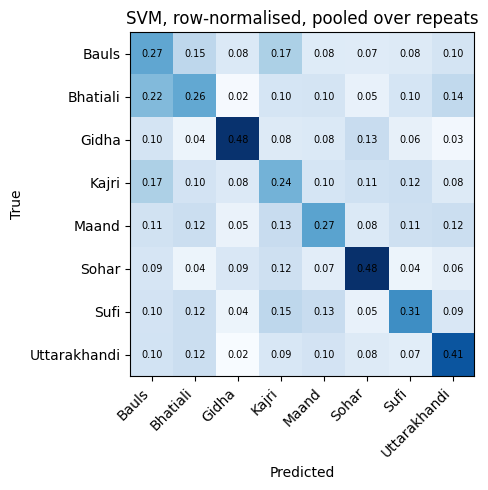

Largest off-diagonal confusions (true -> predicted):
      Bhatiali -> Bauls        0.22
         Bauls -> Kajri        0.17
         Kajri -> Bauls        0.17
         Bauls -> Bhatiali     0.15
          Sufi -> Kajri        0.15
      Bhatiali -> Uttarakhandi 0.14
          Sufi -> Maand        0.13
         Maand -> Kajri        0.13


In [14]:
res, cms, f1g = RUNS["song-grouped"]
print("Per-genre F1 (SVM, song-grouped), mean and SD over repeats:")
display(f1g[f1g.model == "SVM (RBF)"].drop(columns="model").agg(["mean", "std"]).round(2))
cm = cms["SVM (RBF)"]; cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.2, 5)); ax.imshow(cmn, cmap="Blues")
ax.set_xticks(range(len(genres)), genres, rotation=45, ha="right"); ax.set_yticks(range(len(genres)), genres)
for i_, j_ in itertools.product(range(len(genres)), repeat=2):
    ax.text(j_, i_, f"{cmn[i_, j_]:.2f}", ha="center", va="center", fontsize=7, color="white" if cmn[i_, j_] > .5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("SVM, row-normalised, pooled over repeats"); plt.tight_layout(); plt.show()
off = [(genres[i_], genres[j_], cmn[i_, j_]) for i_ in range(len(genres)) for j_ in range(len(genres)) if i_ != j_]
print("Largest off-diagonal confusions (true -> predicted):")
for a_, b_, v in sorted(off, key=lambda t: -t[2])[:8]: print(f"  {a_:>12} -> {b_:<12} {v:.2f}")